In [1]:
#Required packages
import numpy as np 
import os
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.integrate import quad
from scipy.optimize import root
import matplotlib.colors as colors

#Necessary constants 
mu_MgSiO3 = 100.387 #Molar mass of pure enstatite in g/mol
mu_Fe = 55.845 #Molar mass of pure iron in g/mol
kB = 1.38e-23 #J/K Boltzmann's constant
N_avo = 6.022e23   #Avogadro's number
R = 8.314462618 #ideal gas constant in J/(mol K)
eV_to_J = 1.60218e-19 #Energy conversion from eV to J

In [2]:
#Load the state variables required in the assembly of the transport property grids from PALEOS
#Refer to the Attia el al. (2026) for open-sourced code for rho and cp
#Change the main directory as needed
main_directory = 'YOUR_DIRECTORY'
os.chdir(main_directory+'\\EOS_Data')


#The grids were built from their exact framework for 2.5 < logT (K) < 4.0 and -4 < logP (GPa) < 3.
#This is a subset of the parameter space PALEOS, relevant for our treatment of Earth-mass USPs.
logT_range = np.linspace(2.5,4.0,200) 
logP_range = np.linspace(-4,3,200)      
T_range, P_range = 10**logT_range, 10**logP_range  #Units: K, GPa
logP_grid, logT_grid = np.meshgrid(logP_range, logT_range)

#Evenly logspaced grid for density rho (g/cm3) and specific isobaric heat capacity cp (J/kg/K), built from PALEOS for this (P,T) space.
logrho_enstatite = np.loadtxt("logrho_enstatite.csv", delimiter=',') 
logrho_iron = np.loadtxt("logrho_iron.csv", delimiter=',')
logcp_enstatite = np.loadtxt("logcp_enstatite.csv", delimiter=',')

### Enstatite Phase Boundaries

In [3]:
##Enstatite has 6 phases to consider:
##liquid (liq), perovskite/bridgmanite (brg), post-perovskite (ppv), orthoenstatie (en), low-pressure clinoenstatite (lpcen) and high-pressure enstatite (hpcen)

##PALEOS phases curves. Taken from Appendix B.2 of Attia el al. (2026)
##liquid <--> solid
def enstatite_T_melt(P):
    if P < 2.55:
        T = 1831 * (1 + P/4.6)**0.33
    else:
        T = 6000 * (P/140)**0.26
    return T

##ppv <--> brg 
##compression of the perovskite structure
def ppv_brg_P_transition(T):
    P = 130 + 7e-3 * (T - 2500)
    return P

##hpcen <--> brg
##pyroxene to perovskite structure change at 12 GPa
def hpcen_brg_P_transition(T):
    return 12

##lpcen <--> en
##Temperature boundary between the two low-pressure phases
def lpcen_en_T_transition(P):
    T = (4.78e-2 + np.sqrt((4.78e-2)**2 - 4*3.59e-5*(15.6-P)))/(2*3.59e-5)
    return T

##Pressure boundary between the low-pressure phases (lpcen, en) and hpcen
##lpcen <--> hpcen, en <--> hpcen
def hpcen_en_lpcen_P_transition(T):
    P_hpcen_en = 4.2 + 2.1e-3*T
    P_hpcen_lpcen = 6.94 - 4e-4*T
    if T<1100:
        P = P_hpcen_lpcen
    else:
        P = P_hpcen_en
    return P

## Transport properties parametrization from relevant references for enstatite (MgSiO$_3$).

### Viscosity ($\eta$) in Pa$\cdot$s

In [4]:
#Luo et al. (2021) low-temperature fit
#Fit for liquid enstatite at 2200K < T < 3000K, 0 to 140 GPa
#While fit for T > 2200 K, the authors show that the Vogel-Fulcher-Tammann well predict previous T ~ 2100K data when the fit is extrapolated to low-T
#Used for P<140 GPa 2100 K < T < 3000 
def eta_Luo_2021_lowT(P,T):
    value = np.exp(-8.53 + 0.325*P - 0.0247*P**2 + (6851 - 651*P + 54.8*P**2)/(T-1000))
    return value

#Luo et al. (2021) high-temperature fit
#Valid for liquid enstatite for 3500K < T < 5000K, P < 140 GPa and used in that range
def eta_Luo_2021_highT(P,T):
    value = np.exp(-8. + 0.00377*P - 0.000315*P**2 + (5470 + 123*P + 0.963*P**2)/(T-1000))
    return value

#Use a hermite cubic spline to smooth the transition between the two fits of Luo et al. (2021)
#cubic weights
def weight(x):
    return 6*x**5 - 15*x**4 + 10*x**3

#Covering the 3000K < T < 3500K, P < 140 GPa gap for liquid enstatite
def eta_Luo_2021_midT(P,T):
    x = (T - 3000)/(3500-3000)
    weights = weight(x)
    logeta1 = np.log10(eta_Luo_2021_lowT(P,3000))
    logeta2 = np.log10(eta_Luo_2021_highT(P,3500))
    logvalue = (1-weights)*logeta1 + weights*logeta2
    return 10**logvalue

#Cochain et al. (2017), Low-pressure, near-solidus, gap not covered by Luo et al. (2021).
#We performed our own Arrehnius fit based on MgSiO3 data from Cochain et al. (2017) (see their Figure 3).
#Based on P < 5 GPa, 1878 K < T < 2100 K data
#Applied for T < 2100 K liquid enstatite
def eta_Cochain_2017(P,T):
    value = np.exp(-3.980 + 0.313*P - 0.0286*P**2 + (714 - 192*P + 12.5*P**2)/(T-1698))
    return value
    
#High compression data of Luo & Deng (2025)
#Fit from 5000 K < T < 8000K, P < 1200 GPa and used in that range
def eta_Luo_2025_lowT(P,T):
    value = np.exp(-4.544 - 0.029*P + 0.0411*P**2/1000 + (-7504 + 225*P - 0.282*P**2)/(T-1000))
    return value
     
#Higher compression data from Luo & Deng (2025)
#Fit for high temperatures of 8000 K < T < 14000 K, P < 1200 GPa
#Used in that range but also extrapolated to P > 1200 GPa in lack of better experimental constraints
#Note such compression is not reached in the mantle of Earth-mass planets with core mass fraction (33%)
def eta_Luo_2025_highT(P,T):
    value = np.exp(-8.008 + 0.00366*P - 0.00282*P**2/1000 + (15596 + 1.979*P + 0.0196*P**2)/(T-1000))
    return value

### Effective creep viscosity of the solid phases
    
#Bystricky et al. (2024), effective viscosity of orthoenstatite (en) (See their figure 6), used for clinoenstatite as well in lack of data
#We invert their Equation 2 to get the stress from the creep rate
#Assume a strain rate of 10^-15 s^-1.
def eta_Bystricky_2024(T):
    A, eps_strain, Q = 10**6.4, 1e-15, 577 
    #Units: A in s^-1, eps_strain in s^-1, Q in kJ/mol
    
    stress = (eps_strain/A * np.exp(Q*1e3/(R*T)))**(1/3.5) #MPa
    eta_value = stress*1e6/(3*eps_strain) #Pa s
    return eta_value

#Tsujino et al. (2022), effective viscosity of bridgmanite (brg) (see their Table S2 and Figure 6)
# Anchored to 25 GPa and 1900 K bridgmanite. 
#Taking their D111 all data combination with n=3.5 for dislocation creep
def eta_Tsujino_2022(T):
    A, eps_strain, H = 8.5, 1e-15, 432
    #Units: A in GPa^-3.5 s^-1, eps_strain in s^-1, H in kJ/mol

    stress = ( 10**(-A)*eps_strain*np.exp(H*1e3/(R*T)))**(1/3.5) #GPa
    eta_value = stress*1e9/(3*eps_strain) #Pa s 
    return eta_value

#The effective viscosity of ppv is still debated, due to unknown grain size and anisotropic viscosity.
#No quantitative data to assess this to data.
#According to Tackley et al. (2013), it could range from 2 orders of magnitude less than perovskite (brg) to 5 orders of magnitude greater
#According to Dannberg et al. (2023), it should be ~10-100x weaker than brg.
#We pick 2 orders of magnitude less and note that the ppv phase is not reached in our current calculations
def eta_Dannberg_2023(T):
    return eta_Tsujino_2022(T)/100

### Electrical conductivity ($\sigma_p$) in S/m

In [5]:
#Zhang et al. (2012), electrical conductivity of enstatite as a function of water content
#We use their dry sample En0 (see their Table 1) as there is no reason to assume the mantle of hot USPs should be water-bearing.
#This sample is also almost purely MgSiO3 (see their table S1).
#Lower-mantle iron heterogeneity constrained by the electrical conductivity of Al-bearing bridgmanite]
#Using their Equation 1 with best-fit parameters from their Table 1
#After taking the conductivity measurements, they identified their samples as orthoenstatite (en),
#but also crossing the boundary to clinoenstatite (lpcen since the experiment is conducted at 3 GPa).
def sigma_Zhang_2012(P,T):
    dH0_eV= 1.11 #eV
    dH0 = dH0_eV * eV_to_J #J
    sigma0= 10**(1.09) #S/m
    value = sigma0 * np.exp(-dH0 /(kB*T) ) #S/m
    return value

#Okuda et al. (2024), electrical conductivity of Solid MgSiO3 Bridgmanite (brg) (their Section 4.1)
#They report 3 distinct fits at 36 GPa, 50 GPa and 64 GPa (see their Figure S7), which we combine into a single framework
#We directly use the 65 GPa fit for P>65 GPa, the 37 GPa for P < 37 GPa, and interpolate between the two with a hermite cubic spline.
#The P=65 GPa fit is further extended to ppv in lack of data.

# Data points
P_pts = np.array([37, 65])          # GPa
logsigma0_pts = np.array([1.7245,2.8961])  # log10(S/m)
dH_pts = np.array([1.0957, 1.3011])         # eV

#Base arrhenius relation
def sigma_Okuda_endpoint(idx, T):
    sigma0 = 10**logsigma0_pts[idx]
    dH = dH_pts[idx]
    return sigma0 * np.exp(-dH * eV_to_J / (kB * T)) #S/m

#Combining
def sigma_Okuda_2024_solid(P, T):
    if P <= 37:
        return sigma_Okuda_endpoint(0, T) #S/m

    elif P >= 65:
        return sigma_Okuda_endpoint(1, T) #S/m

    else:
        x = (np.log10(P) - np.log10(37)) / (np.log10(65) - np.log10(37))
        w = weight(x)
    
        log_sigma_37 = np.log10(sigma_Okuda_endpoint(0, T))
        log_sigma_65 = np.log10(sigma_Okuda_endpoint(1, T))
    
        return 10**((1 - w) * log_sigma_37 + w * log_sigma_65) #S/m

#Okuda et al. (2024), electrical conductivity of molten MgSiO3 (their Section 4.2)
#We adopt their global activation energy form their Figure S8.
#This parameter set represents a general behaviour over the pressure range, but they again present different fits for different values.
#Due to the limited amount of points of each indiviual fit, we adopt their global fit.
def sigma_Okuda_2024_liquid(P, T):
    dH = 2.13 #eV 
    sigma0 = 1.3e4 #S/m
    return sigma0 * np.exp(-dH* eV_to_J / (kB * T))

### Thermal conductivity ($k_{\rm cond}$) in (W/m/K)

In [6]:
#Maierová et al (2012), thermal conductivity of MgSiO3 clinopyroxene
#their cpx model which corresponds to both high and low pressure clinopyroxene in PALEOS (lpcen & hpcen)
#We make use of the known PALEOS properties rho and cp
def k_cond_Maierova_2012(P,T,rho,cp):
    #P in GPa, T in K, rho in g/cm3, cp in J/kg/K

    #Diffusion coefficient at reference pressure from their Table 2
    D_ref = 1/(-0.138 + 0.00173*T - 3.24e-7*T**2) #mm2/s
    
    #Pressure dependent correction parameters from their Table 2
    alphap, P_ref = 0.04, 0  #alphap in GPa^-1, P_ref in GPa

    #Linearized Pressure Dependence from their Equation 4
    f = 1 + alphap * (P - P_ref)

    #P-T dependent diffusion coefficient
    D = D_ref * f #mm2/s

    #Compute conductivity in SI units from their Equation 1
    D_SI = D/1e6 #m2/s
    rho_SI = rho*1e3 ##kg/m^3
    k_SI = D_SI * rho_SI * cp #W/m/K
    return k_SI

#Guo et al. (2024), thermal conductivtiy of orthoenstatite
#Best-fit parameters from their table 4
#En sample for pure MgSiO3
#Global P=1-3 GPa fit for broad pressure coverage
def k_cond_Guo_2024(P,T):
    
    #k0 in W/m/K, n dimensionless, 0.11 dimensionless for pressure in GPa
    k0, n, c = 7.667, 0.736, 0.11

    #Their Equation 3
    value = k0 * (293/T)**n * (1+c*P)
    return value 

#Ohta et al. (2012), thermal conductivity of perovskite enstatite (brg/pv)
#Using their Equation 4 and corresponding fit parameters (see their Section 3.2) 
def k_cond_Ohta_2012_brg(rho,T):
    k_ref = 15.4 #W/m/K
    T_ref=300 #K
    rho_ref=4.89 #g/cm^3
    a=0.43
    g=5.6 
    k_value = k_ref * (T_ref/T)**a * (rho/rho_ref)**g
    return k_value

#Ohta et al. (2012), thermal conductivity of post-perovskite enstatite (ppv)
#Using their Equation 4 and corresponding fit parameters (see their Section 3.2) 
def k_cond_Ohta_2012_ppv(rho,T):
    k_ref = 61.8  #W/m/K
    T_ref=300 #K
    rho_ref=5.6 #g/cm^3
    a=0.43  #Taken to be the same as pv due to limited data for ppv (see their Figure 7)
    g=6.0 
    k_value = k_ref * (T_ref/T)**a * (rho/rho_ref)**g
    return k_value

# Deng & Stixrude (2021), thermal conductivity of liquid MgSiO3.
# Parametrization with best-fit coefficients from their Equation 5 and section 3.3
def k_cond_Deng_2021(rho,T):
    k_ref = 1.16 #W/m/K
    T_ref=3000 #K
    V_ref = 38.9 #cm3/mol
    rho_ref= 1/V_ref * mu_MgSiO3 #g/cm^3
    a=-0.09
    g=1.75
    k_value = k_ref * (T_ref/T)**a * (rho/rho_ref)**g #W/m/K
    return k_value

## Enstatite grid assembly

In [7]:
#Function to compute the transport properties
def logtransport_enstatite(P,T,rho,cp):
    #Input: P(GPa), T(K), rho(g/cm3), cp(J/kg/T)

    #Phase boundaries
    #Liquid <--> solid
    T_melt = enstatite_T_melt(P)
    #ppv <--> brg
    P_ppv_brg = ppv_brg_P_transition(T)
    #hpcen <--> brg
    P_hpcen_brg = hpcen_brg_P_transition(T)
    #hpcen <--> en <--> lpcen pressure transition
    P_hpcen_en_lpcen = hpcen_en_lpcen_P_transition(T)
    #lpcen <--> en temperature transition
    T_lpcen_en = lpcen_en_T_transition(P)    

    #Liquid phase
    if T > T_melt:  
        ###Viscosity

        #Luo el al. (2021)
        #Low T
        if (P<140)&(2100<=T)&(T<3000):
            eta_value = eta_Luo_2021_lowT(P,T)
        #High T
        elif (P<140)&(3500<=T)&(T<5000):
            eta_value = eta_Luo_2021_highT(P,T) 
        #Smooth transition
        elif (3000<=T)&(T<3500):
            eta_value = eta_Luo_2021_midT(P,T) 

        #Luo & Deng (2025)
        #Low T
        elif (T >= 5000) & (T < 8000) & (P<1200):
            eta_value = eta_Luo_2025_lowT(P,T)
        #High T
        elif (T >= 8000) & (T < 14000) & (P<1200):
            eta_value = eta_Luo_2025_highT(P,T)
        #Extrapolate the Luo & Deng (2025) fit to even higher P in lack of data
        elif (P>=1200):
            eta_value = eta_Luo_2025_highT(P,T)
        #Low-T near-solidus gap not covered by Luo et al. (2021)
        #T < 2100 K (liquid for P < 3 GPa)
        else:
            eta_value = eta_Cochain_2017(P,T)

        ###Electrical conductivity
        sigma_value = sigma_Okuda_2024_liquid(P,T)

        ###Thermal conductivity
        k_cond_value = k_cond_Deng_2021(rho,T)
                         
    #ppv phase        
    elif P > P_ppv_brg:
        
        ###Viscosity
        eta_value = eta_Dannberg_2023(T)
       
        ###Electrical conductivity
        sigma_value = sigma_Okuda_2024_solid(P,T)

        ###Thermal conductivity
        k_cond_value = k_cond_Ohta_2012_ppv(rho,T)
    
    #brg phase
    elif P > P_hpcen_brg: 
        
        ###Viscosity
        eta_value = eta_Tsujino_2022(T)
        
        ###Electrical conductivity
        sigma_value =sigma_Okuda_2024_solid(P,T)
        
        ###Thermal conductivity
        k_cond_value = k_cond_Ohta_2012_brg(rho,T)

    #hpcen
    elif P > P_hpcen_en_lpcen:
        
        ###Viscosity
        eta_value = eta_Bystricky_2024(T)
        
        ###Electrical conductivity
        #For electrical conductivity, impose a hermite cubic spline to smoothen the transition between en/lpcen (Zhang_2012) and brg (Okuda_2024)
        x = (np.log10(P) - np.log10(P_hpcen_en_lpcen))/(np.log10(P_hpcen_brg) - np.log10(P_hpcen_en_lpcen))
        weights = weight(x)
        logsigma1 = np.log10(sigma_Zhang_2012(P_hpcen_en_lpcen,T) )
        logsigma2 = np.log10(sigma_Okuda_2024_solid(P_hpcen_brg,T))
        logvalue = (1-weights)*logsigma1 + weights*logsigma2
        sigma_value = 10**logvalue
        
        ###Thermal conductivity
        k_cond_value = k_cond_Maierova_2012(P,T,rho,cp)
        
    #lpcen
    elif T < T_lpcen_en:
        
        ###Viscosity
        eta_value = eta_Bystricky_2024(T)
        
        ###Electrical conductivity
        sigma_value = sigma_Zhang_2012(P,T)    
        
        ###Thermal conductivity
        k_cond_value = k_cond_Maierova_2012(P,T,rho,cp)

    #en
    else: 
        
        ###Viscosity
        eta_value = eta_Bystricky_2024(T)
        
        ###Electrical conductivity
        sigma_value = sigma_Zhang_2012(P,T)
        
        ###Thermal conductivity
        k_cond_value = k_cond_Guo_2024(P,T)

    #Return log eta, log sigma_p, log k_cond in Pa s, S/m and W/m/K
    return np.log10(eta_value), np.log10(sigma_value), np.log10(k_cond_value)

#Create log-spaced grids for each transport properties
logeta_enstatite = np.zeros((len(logP_range), len(logT_range)))
logsigma_enstatite = np.zeros((len(logP_range), len(logT_range)))
logk_cond_enstatite = np.zeros((len(logP_range), len(logT_range)))

#Evaluate the transport properties as functions of P,T                       
for i, logP in enumerate(logP_range):
    for j, logT in enumerate(logT_range):
        #Use rho and cp from the PALEOS imported grids
        P,T, rho, cp  = 10**logP, 10**logT, 10**logrho_enstatite[i,j],10**logcp_enstatite[i,j]

        #Evaluate the transport properties in the parameter space where the PALEOS grids are resolved
        if np.isnan(logrho_enstatite[i,j])==False:
            logeta_enstatite[i,j], logsigma_enstatite[i,j], logk_cond_enstatite[i,j] = logtransport_enstatite(P_range[i],T_range[j],10**logrho_enstatite[i,j],10**logcp_enstatite[i,j])
        #Set everything else to Nan. This corresponds to an unresolved vaporization regime.
        else:
            logeta_enstatite[i,j], logsigma_enstatite[i,j], logk_cond_enstatite[i,j] = np.nan,np.nan,np.nan

### Grids vizualization

In [8]:
####Phase curves for plotting, see Appendix B of Attia et al. (2026)

# lpcen <---> hpcen
phase_curve_lpcen_hpcen = 6.94 - 4e-4*T_range
# en <---> hpcen
phase_curve_en_hpcen = 4.2 + 2.1e-3*T_range
#hpcen <---> lpcen/en
phase_curve_en_lpcen_hpcen = phase_curve_lpcen_hpcen
phase_curve_en_lpcen_hpcen[T_range>1100] = phase_curve_en_hpcen[T_range>1100]
#lpcen <---> en
phase_curve_lpcen_en = 15.6 - 4.78e-2*T_range + 3.59e-5 * T_range**2
#prevent the curves from going negative
phase_curve_lpcen_en[T_range<665] = 1e-30
#hpcen <---> brg
phase_curve_hpcen_brg = 12 + 0*T_range
#Brg <---> ppv
phase_curve_brg_ppv = 130 + 7e-3*(T_range - 2500)
#Solid <---> liquid, low pressures
phase_curve_melt_low = 1831 * (1 + P_range/4.6)**0.33
#Solid <---> liquid, high pressures
phase_curve_melt_high = 6000 * (P_range/140)**0.26
#Crossing pressure of the melting expressions
cross = 2.55
#Global melting curves 
phase_curve_melt = phase_curve_melt_low
phase_curve_melt[P_range>2.55] = phase_curve_melt_high[P_range>2.55]
#Build an interpolator to compute the melting pressure as a function of T
solidus_fun = interp1d(phase_curve_melt,P_range,bounds_error=False,fill_value=(1e-30,1e-30))
P_solidus = solidus_fun(T_range)

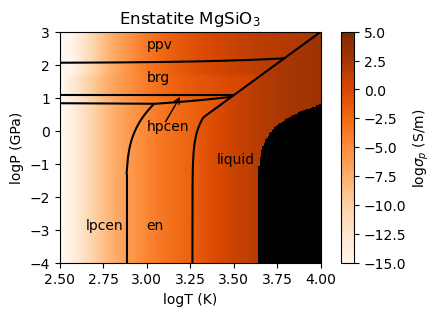

In [9]:
###Electrical conductivity of enstatite

#Move the "Figures" directory to make the figures
os.chdir(main_directory+'//Figures')
fig = plt.figure(figsize=(3.8,3))

# Grid: main plot on left, single colorbar on right
gs = fig.add_gridspec(1, 2, width_ratios=[20, 1], wspace=0.15)
ax = fig.add_subplot(gs[0, 0])        # main axes
cax = fig.add_subplot(gs[0, 1])       # single colorbar axis

#Plot the phase curves
ax.plot(logT_range[phase_curve_en_lpcen_hpcen/P_solidus>1],np.log10(phase_curve_en_lpcen_hpcen[phase_curve_en_lpcen_hpcen/P_solidus>1]),color='k')
ax.plot(logT_range[(phase_curve_lpcen_en/P_solidus>1)&(phase_curve_lpcen_en/phase_curve_en_lpcen_hpcen<1)],np.log10(phase_curve_lpcen_en[(phase_curve_lpcen_en/P_solidus>1)&(phase_curve_lpcen_en/phase_curve_en_lpcen_hpcen<1)]),color='k')
ax.plot(logP_range[logP_range<-1.3]*0 + 2.885,logP_range[logP_range<-1.3],color='k')
ax.plot(logT_range[phase_curve_brg_ppv/P_solidus>1],np.log10(phase_curve_brg_ppv[phase_curve_brg_ppv/P_solidus>1]),color='k')
ax.plot(logT_range[phase_curve_hpcen_brg/P_solidus>1],np.log10(phase_curve_hpcen_brg[phase_curve_hpcen_brg/P_solidus>1]),color='k')
ax.plot(np.log10(phase_curve_melt),logP_range,'k-')

#Plot NaNs in masked black region
nan_layer = np.isnan(logeta_enstatite.T)

# Mask everything except NaNs
nan_plot = np.ma.masked_where(~nan_layer,logeta_enstatite.T)

# A colormap that treats masked values as black
black_cmap = colors.ListedColormap(['black'])
black_cmap.set_bad('black')

#Shade the unresolved parameter space
ax.pcolormesh(logT_grid, logP_grid, nan_plot,
              cmap=black_cmap, rasterized=True)

# Single colormap and normalization
cmap = plt.cm.Oranges
pcm = ax.pcolormesh(logT_grid, logP_grid, logsigma_enstatite.T,
                    cmap=cmap, vmin=-15, vmax=5, rasterized=True)

# Correct colorbar placement
cbar = fig.colorbar(pcm, cax=cax)
cbar.set_label('log$\\sigma_p$ (S/m)')

#Annotate the phases
ax.annotate('liquid',(3.4,-1))
ax.annotate('brg',(3.0,1.5),)
ax.annotate('ppv',(3.0,2.5),)
ax.annotate('en',(3,-3),)
ax.annotate('lpcen',(2.65,-3),)
ax.annotate('hpcen',(3,0),)
ax.annotate(
    "", xy=(3.2, 1.1), xytext=(3.1, 0.2),
    arrowprops=dict(arrowstyle="->", lw=1, )
)

#Finalize and save the figure
ax.set_xlabel('logT (K)')
ax.set_ylabel('logP (GPa)')
ax.set_title('Enstatite MgSiO$_3$')
ax.set_xlim((2.5, 4))
ax.set_ylim((-4, 3))
plt.savefig("mantle_sigma_p_EOS.pdf", bbox_inches='tight')

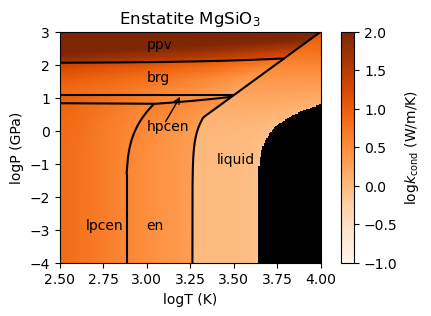

In [10]:
###Thermal conductivity of enstatite

fig = plt.figure(figsize=(3.8,3))

# Grid: main plot on left, single colorbar on right
gs = fig.add_gridspec(1, 2, width_ratios=[20, 1], wspace=0.15)
ax = fig.add_subplot(gs[0, 0])        # main axes
cax = fig.add_subplot(gs[0, 1])       # single colorbar axis

#Plot the phase boundaries
ax.plot(logT_range[phase_curve_en_lpcen_hpcen/P_solidus>1],np.log10(phase_curve_en_lpcen_hpcen[phase_curve_en_lpcen_hpcen/P_solidus>1]),color='k')
ax.plot(logT_range[(phase_curve_lpcen_en/P_solidus>1)&(phase_curve_lpcen_en/phase_curve_en_lpcen_hpcen<1)],np.log10(phase_curve_lpcen_en[(phase_curve_lpcen_en/P_solidus>1)&(phase_curve_lpcen_en/phase_curve_en_lpcen_hpcen<1)]),color='k')
ax.plot(logP_range[logP_range<-1.3]*0 + 2.885,logP_range[logP_range<-1.3],color='k')
ax.plot(logT_range[phase_curve_brg_ppv/P_solidus>1],np.log10(phase_curve_brg_ppv[phase_curve_brg_ppv/P_solidus>1]),color='k')
ax.plot(logT_range[phase_curve_hpcen_brg/P_solidus>1],np.log10(phase_curve_hpcen_brg[phase_curve_hpcen_brg/P_solidus>1]),color='k')
ax.plot(np.log10(phase_curve_melt),logP_range,'k-')

#Mask the unsolved EOS parameter space
ax.pcolormesh(logT_grid, logP_grid, nan_plot,
              cmap=black_cmap, rasterized=True)

# Single colormap and normalization
cmap = plt.cm.Oranges
pcm = ax.pcolormesh(logT_grid, logP_grid, logk_cond_enstatite.T,
                    cmap=cmap, vmin=-1, vmax=2, rasterized=True)

# Correct colorbar placement
cbar = fig.colorbar(pcm, cax=cax)
cbar.set_label('log$k_{\\rm cond}$ (W/m/K)')

#Annotate the phase boundaries
ax.annotate('liquid',(3.4,-1))
ax.annotate('brg',(3.0,1.5),)
ax.annotate('ppv',(3.0,2.5),)
ax.annotate('en',(3,-3),)
ax.annotate('lpcen',(2.65,-3),)
ax.annotate('hpcen',(3,0),)
ax.annotate(
    "", xy=(3.2, 1.1), xytext=(3.1, 0.2),
    arrowprops=dict(arrowstyle="->", lw=1, )
)

#Finalize and save the Figure
ax.set_title('Enstatite MgSiO$_3$')
ax.set_xlim((2.5, 4))
ax.set_ylim(((5-9), (12-9)))
ax.set_xlabel('logT (K)')
ax.set_ylabel('logP (GPa)')
plt.savefig('mantle_k_cond_EOS.pdf',bbox_inches='tight')

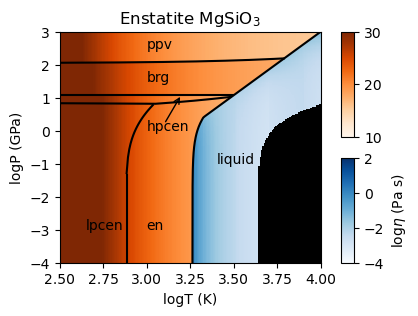

In [11]:
###Viscosity of Enstatite
fig = plt.figure(figsize=(3.8,3))

# Grid: main plot on left, two stacked colorbars on right
gs = fig.add_gridspec(2, 2, width_ratios=[20, 1], wspace=0.15)
ax = fig.add_subplot(gs[:, 0])        # main axes
cax_low  = fig.add_subplot(gs[1, 1])  # bottom colorbar
cax_high = fig.add_subplot(gs[0, 1])  # top colorbar

#Plot the phase boundaries
ax.plot(logT_range[phase_curve_en_lpcen_hpcen/P_solidus>1],np.log10(phase_curve_en_lpcen_hpcen[phase_curve_en_lpcen_hpcen/P_solidus>1]),color='k')
ax.plot(logT_range[(phase_curve_lpcen_en/P_solidus>1)&(phase_curve_lpcen_en/phase_curve_en_lpcen_hpcen<1)],np.log10(phase_curve_lpcen_en[(phase_curve_lpcen_en/P_solidus>1)&(phase_curve_lpcen_en/phase_curve_en_lpcen_hpcen<1)]),color='k')
ax.plot(logP_range[logP_range<-1.3]*0 + 2.885,logP_range[logP_range<-1.3],color='k')
ax.plot(logT_range[phase_curve_brg_ppv/P_solidus>1],np.log10(phase_curve_brg_ppv[phase_curve_brg_ppv/P_solidus>1]),color='k')
ax.plot(logT_range[phase_curve_hpcen_brg/P_solidus>1],np.log10(phase_curve_hpcen_brg[phase_curve_hpcen_brg/P_solidus>1]),color='k')
ax.plot(np.log10(phase_curve_melt),logP_range,'k-')

#Mask the nan regions
ax.pcolormesh(logT_grid, logP_grid, nan_plot,
              cmap=black_cmap, rasterized=True)

# Masked ranges
#Liquid/near-liquid low values
logeta_low  = np.ma.masked_outside(logeta_enstatite.T, -4, 2)
#Solid creep viscosities
logeta_high = np.ma.masked_outside(logeta_enstatite.T, 10, 90)

# Two different colormaps
cmap_low  = plt.cm.Blues
cmap_high = plt.cm.Oranges

# Plot masked layers
pcm_low = ax.pcolormesh(logT_grid, logP_grid, logeta_low,
                        cmap=cmap_low, vmin=-4, vmax=2, rasterized=True)

pcm_high = ax.pcolormesh(logT_grid, logP_grid, logeta_high,
                         cmap=cmap_high, vmin=10, vmax=30, rasterized=True)

# Bottom colorbar: -4 to 2
cbar_low = fig.colorbar(pcm_low, cax=cax_low)
cbar_low.set_label('log$\\eta$ (Pa s)')
cbar_low.ax.set_ylim(-4, 2)
cbar_low.ax.spines['top'].set_visible(False)

# Top colorbar: 10 to 30
cbar_high = fig.colorbar(pcm_high, cax=cax_high)
cbar_high.ax.set_ylim(10, 30)
cbar_high.ax.spines['bottom'].set_visible(False)

#Annotate the phases
ax.annotate('liquid',(3.4,-1))
ax.annotate('brg',(3.0,1.5),)
ax.annotate('ppv',(3.0,2.5),)
ax.annotate('en',(3,-3),)
ax.annotate('lpcen',(2.65,-3),)
ax.annotate('hpcen',(3,0),)
ax.annotate(
    "", xy=(3.2, 1.1), xytext=(3.1, 0.2),
    arrowprops=dict(arrowstyle="->", lw=1, )
)


#Finalize and save the figure
ax.set_title('Enstatite MgSiO$_3$')
ax.set_xlim((2.5, 4))
ax.set_ylim((-4, 3))
ax.set_xlabel('logT (K)')
ax.set_ylabel('logP (GPa)')
plt.savefig("mantle_eta_eff_EOS.pdf", bbox_inches='tight')

### Iron Phase Boundaries

In [12]:
##Iron has 5 phases to consider:
##liquid (liq), ambient condition body-centered cubic phase (alpha-bcc), transitional face-centered cubic phase (gamma-fcc), 
#hexagonal close-packed phase (epsilon-hcp) and near-melting body-centered cubic phase (delta-bcc) 

##PALEOS phases curves. Taken from Appendix B.2 of Attia el al. (2026)
#P in GPa, T in K

#liquid <---> solid 
def iron_solidus(P):
    P0, T0 = 5.2, 1991 #GPa, K
    Pt, Tt = 98.5, 3712 #GPa,K
    #Combinining complementary parametrization
    if (P0 < P) & (P < Pt):
        T_melt = T0 * (1 + (P-P0)/27.39)**(1/2.38)
    elif (P > Pt):
        T_melt = Tt * (1 + (P-Pt)/161.2)**(1/1.72)
    else:
        T_melt = T0
    return T_melt

#gamma-fcc <-----> epsilon-hcp
def gamma_epsilon_phase(P):
    T = 575 + 18.7 *P + 0.213 * P**2 - 8.17e-4 * P**3
    return T

#alpha-bcc <----> gamma-fcc
def alpha_gamma_phase(P):
    T = 1120 - 300 * P/7.3
    return T

#delta-bcc <----> gamma-fcc
def delta_gamma_phase(P):
    T = 1580 +418 * P/5.2
    return T

#alpha-bcc <----> epsilon-hcp
def alpha_epsilon_phase(P):
    T = 820 - 520 * (P - 7.3)/8.5
    return T

## Transport properties parametrization from relevant references for iron (Fe).

### Viscosity ($\eta$) in Pa$\cdot$s

In [13]:
#Assael et al. (2006), viscosity of liquid iron at room pressure
#See their Equation (20) and Fig. 13
#Fitted over 1809 K < T < 2480 K data
#Conducted at ambiant pressure for densities < 7.1 g/cm^3
#Used in this parameter space
def eta_Assael_2006(P,T):
    eta0 = 1e-3 #Pa s, Reference viscosity
    a3,a4 = 0.7209, 2694.95 #Fit parameters
    eta = eta0 * 10**(-a3 + a4/T) # Pa s, viscosity value
    return eta

#Kono et al. (2015), viscosity of liquid iron at intermediary pressure
#Arrheniuis fit over 1800 K < T < 2150 K (see their Equation 6)
#Used for P < 6.5 GPa and 1873 K < T < 2043 K.
def eta_Kono_2015(P,T):
    eta0 = 0.2e-3  #\pm 0.01 Pa s, reference viscosity
    Q = 51.6e3 #J/mol, Activation energy
    dV = 1.29e-6 #m3/mol, Activation volume
    eta = eta0 * np.exp( (Q + P * 1e9 * dV)/(R * T)) #Pa s
    return eta

#Luo et al. (2026), viscosity of liquid iron at high core-like compression P > 100 GPa
#Fit over 3000 K (solidus) < T < 7000K and rho > 10.7 g/cm^3
#Their Arrehenius fit (Equation 2)
#Extrapolated to 10,000K in lack of data.
def eta_Luo_2026(P,T):
    a0, a1, a2, a3 = 0.203, - 1.34e-3, 4e3, 45.5 #Fit constants
    lneta = a0 + a1*P + a2/T + a3*P/T #Viscosity map
    eta = np.exp(lneta)/1000 #Pa s
    return eta

#Weights for Hermite cubic spline between Luo26 and Kono15
def rho_weight(rho, rho_c, drho):
    return 1/2 * (1- np.tanh( (rho - rho_c)/drho))

#Jackson et al. (2000), viscoelastic relaxation of iron 
#Fitted to data from their Table 6 for alpha-bbc
def eta_Jackson_2000_bcc(T):
    #R in J/mol/K, #T in K
    log_eta0_bcc = 17.80 #Log Pa*s
    E_bcc = 74.04 #kJ/mol
    return np.exp(log_eta0_bcc + E_bcc*1e3/(R*T))

#Jackson et al. (2000), viscoelastic relaxation of iron 
#Fitted to data from their Table 6 for delta-fcc
def eta_Jackson_2000_fcc(T):
    #R in J/mol/K, #T in K
    log_eta0_fcc = 19.36 #log Pa s
    E_fcc = 95.59 #kJ/mol
    return np.exp(log_eta0_fcc + E_fcc*1e3/(R*T))

#Belonoshko et al. (2019), Viscosity of solid bcc iron in Earth's iron core condition
#The near-melting resurgence is fluid-like, with ~40x higher viscosity than liquid values
def eta_belonoshko_2019(P,T):
    return 40*eta_Kono_2015(P,T)

#Nishihara et al. (2023), Rheology of Hexagonal Close-Packed (hcp) Iron
#Power law creep. See their discussion for assumed flow rate
#Using their Equation 2, valid for T > 800K
def stress_Nishihara_2023_highT(P,T):
    A, eps_strain, n, E, V  = 10**(12.5), 1e-15, 4, 240, 1.4
    #A s-1 GPa^-n 
    #Eps_strain in s-1
    #E kJ/mol
    #V cm3/mol
    #Assume a strain rate
    #compute the stress
    stress = (eps_strain/A * np.exp( (E*1e3 + (P*1e9) * (V*1e-6))/(R*T)))**(1/n) #GPa
    return stress

#Nishihara et al. (2023), Rheology of Hexagonal Close-Packed (hcp) Iron
#Low T creep. See their discussion for assumed flow rate
#Using their Equation 2, valid for T < 800K
def stress_Nishihara_2023_lowT(P,T):
    A, eps_strain, n, E, V, stress_P, p, q = 10**5.4, 1e-15, 5, 148, 0.9, 2.3, 1, 0.1
    #A s-1 GPa^-n 
    #Eps_strain in s-1
    #E kJ/mol
    #V cm3/mol
    #sigma_P in GPa
    #Assume a stress 
    #define a function to solve for the stress implicetely
    #Cap the differential stress at the Peierls stress where the creep law converges
    root_fun = lambda s: A * min(s,stress_P)**n * np.exp( -(E*1e3 + (P*1e9) * (V*1e-6))/(R*T) * (1 - (min(s,stress_P)/stress_P)**p)**q) - eps_strain
    #compute the stress
    sol = root(root_fun,x0=1)
    stress = float(sol.x) #GPa
    return stress

#Nishihara et al. (2023), Rheology of Hexagonal Close-Packed (hcp) Iron
#In reality, the true differential stress will be the minimum of the different possible regimes 
#stress_eff=min(stress_highT,stress_lowT,stress_P)
def eta_Nishihara_2023(P, T):
    stress_highT = stress_Nishihara_2023_highT(P,T) #GPa
    stress_lowT = stress_Nishihara_2023_lowT(P,T) #GPa
    stress_P = 2.3 #GPa
    eps_strain = 1e-15 #s-1
    stress_array = np.array([stress_highT, stress_lowT, stress_P])
    #Effective stress
    stress_eff = np.amin(stress_array)
    eta_value = stress_eff*1e9/(3*eps_strain) #Pa s
    return eta_value

### Electrical conductivity ($\sigma_p$) in S/m and thermal conductivity ($k_{\rm cond}$) in W/m/K.

In [14]:
#Koker et al. (2012), electrical and thermal conductivity of liquid Fe
#Self-consistent theoretical framework for thermal and electrical conductivity for liquid iron.
#Tested at 2000-8000K, 1 GPa to ~350 GPa, see their Figure 1.
#Extrapolated up to 10,000K and 1000 GPa for grid construction in lack of additional data
def sigma_k_cond_Koker_2012(T,rho):
    #Fit parameters taken from their Table 1 for pure Fe
    r0R = 0.77e-6 #Ohm m, Reference resistivity 0th order in T
    r1R = 0.084e-6 #Ohm m, Reference resistivity 1st order in T
    T_R = 3000  #K, Reference T 
    V_R = 7 #cm3/mol atom, Reference V
    rho_R =   mu_Fe/V_R #g/cm3, Reference density 
    lamda_R = 2.25e-8 #W Ohm/K^2, Reference Lorenz number
    X = rho_R/rho    #Normalized volume/density
    Y = T/T_R        #Normalized temperature
    a,b,c,d = 0.77,1.29,-0.078,-0.057 #Fitted constant representing the dependence on vibrational frequencies.

    #Their Equation 4, V-T dependent electrical resistivity
    r_el = (r0R * X**a + r1R * X**b * Y) #Ohm m, eletrical resistivity

    #Their Equation 6, V-T dependent Lorrenz number
    lamda = lamda_R * X**c * Y**d #W Ohm/K^2, Lorenz number

    #Inverting resistivity for conductivity
    sigma = 1/r_el    #S/m,electrical conductivity 

    #Self-consistent electronic thermal conductivity
    k_cond = lamda * T / r_el #W/m/K, thermal conductivity 
    
    #Return both parameters at once
    return sigma, k_cond

#Sah & cohen (2011), calcualtions of the electrical conductivity for alpha-bcc at low-T
#Fitted for 7.3 < rho < 9, 85 bohr^3/atom > V > 70 bohr^3/atom, T < 500K
#Used and extrapolated up to  T < 1120K.
def sigma_Sha_2011(rho,T):
    #Fit parameters 
    c0,c1,c2,c3 = 0.4571,-.1016,-0.0315,0.001787
    #Units: 10^-8 Ohm m, 10^-8 Ohm m / K, 10^-8 Ohm m / (bohr^3/atom), 10^-8 Ohm m / K / (bohr^3/atom)

    #Volume in bohr^3/atom
    V = 625.792/rho
    
    #Electric resistivity
    res = c0 + c1*T + c2*V + c3*V*T #10^-8 Ohm m
    sigma = 1/ (res * 1e-8) #S/m
    return sigma 

#Nikolov et al. (2022), analysis of different components of k_cond for alpha-bbc iron
#Material is allowed to expand, equilibrating at pressures P ~ 0GPa
#Little to no pressure dependence for the ambient pressure alpha-bcc phase
#Fit for 300K < T <1250K. 
#Alpha-bcc is present from T < 1120 K at low P.
def k_cond_Nikolov_2012(P,T):
    #Fit parameters
    A = 42855 #W/m
    B = 234 #K
    
    #Analytical valid over the given range
    k_cond = A / (T + B) #W/m/K 
    return k_cond

#Kleinschimdt et al. (2023), self-consistent electrical and thermal conductivity of fcc iron
#Using fits from their Equation 6 & 7, along with best-fit parameters from their Table 2
#Tested for 1000K < T < 7000K, 8 g/cm3 < rho < 13.5 g/cm^3
#We use this relation for 760K < T < 3700K, 7.4 g/cm3 < rho < 10.2 g/cm^3
def sigma_k_cond_Kleinshmidt_2023_fcc(rho,T):
    
    #Fit coefficients for electrical conductivity
    c0, c1, c2, c3 = -2477e6, 1434e6, 0.933e6, -1228e6 
    #Units: S/m K, S/m cm^3/g K, S/m, S/m K 

    #Compute T * sigma from their Equation 6
    Tsigma = c0 + c1*rho + c2*T + c3*np.log(T) #S/m K

    #Retrieve the electrical conductivity alone
    sigma = Tsigma/T #S/m

    #Fit coefficients for thermal conductivity
    d0, d1, d2, d3 = -137.1, 35.29, 0.02538, -20.07 
    #Units: W/(Km), W/(Km) cm^3/g, W/(km)/K, W/(km)

    #Compute k_cond from their Equation 7
    k_cond = d0 + d1*rho + d2*T + d3*np.log(T) #W/K/m
    
    return sigma, k_cond

#Kleinschimdt et al. (2023), self-consistent electrical and thermal conductivity of hcp iron
#Using fits from their Equation 6 & 7, along with best-fit parameters from their Table 2
#Tested for 1000K < T < 7000K, 8 g/cm3 < rho < 13.5 g/cm^3
#We use this relation for  760K < T < 5750K,  8 g/cm3 < rho < 14.5 g/cm3
def sigma_k_cond_Kleinshmidt_2023_hcp(rho,T):
    
    #Fit coefficients for electrical conductivity in the basal plane
    c0_B, c1_B, c2_B, c3_B = 17490e6, 1136e6, 1.684e6, -3760e6 
    #Units: S/m K, S/m cm^3/g K, S/m, S/m K 

    #Compute T * sigma from their Equation 6
    Tsigma_B = c0_B + c1_B*rho + c2_B*T + c3_B*np.log(T) #S/m K

    #Retrieve the electrical conductivity in the basal plane alone
    sigma_B = Tsigma_B/T #S/m

    #Fit coefficients for electrical conductivity in the zz direction
    c0_zz, c1_zz, c2_zz, c3_zz = 7464e6, 1555e6, 1.101e6, -2708e6 
    #Units: S/m K, S/m cm^3/g K, S/m, S/m K 

    #Compute T * sigma from their Equation 6
    Tsigma_zz = c0_zz + c1_zz*rho + c2_zz*T + c3_zz*np.log(T) #S/m K

    #Retrieve the electrical conductivity in the zz direction
    sigma_zz = Tsigma_zz/T #S/m

    #Directionally averaged values for hcp
    sigma = 2/3 * sigma_B + 1/3 * sigma_zz

    #Fit coefficients for thermal conductivity in the basal plane
    d0_B, d1_B, d2_B, d3_B = 373, 24.35, 0.05051, -82.2
    #Units: W/(Km), W/(Km) cm^3/g, W/(km)/K, W/(km)

    #Compute k_cond in the basal plane from their Equation 7
    k_cond_B = d0_B + d1_B*rho + d2_B*T + d3_B*np.log(T) #W/K/m

    #Fit coefficients for thermal conductivity in the basal plane
    d0_zz, d1_zz, d2_zz, d3_zz = 315.8, 35.19, 0.03958, -83.27
    #Units: W/(Km), W/(Km) cm^3/g, W/(km)/K, W/(km)

    #Compute k_cond in the basal plane from their Equation 7
    k_cond_zz = d0_zz + d1_zz*rho + d2_zz*T + d3_zz*np.log(T) #W/K/m

    #Directionally averaged values for hcp
    k_cond = 2/3 * k_cond_B + 1/3 * k_cond_zz
    
    return sigma, k_cond

#Pozzo & Alfe (2016), electrical conductivity of high-pressure hcp iron
#Fits to their high-pressure results (their Table 1)
#Little to no pressure dependence as the conductivity is saturated at high-pressure
#Fitted over 850 K < T < 6350 K, 301 GPa < P < 365 GPa
#Used for 750 K < T < 10000 K, 300 GPa < P (due to saturation)
def sigma_Pozzo_2016(P,T):
    #Fit parameters
    a0, a1, a2,  = -3.311238e-08 ,1.382998e-10, -7.336196e-15
    #Units: 

    #Electrical resistivity 
    res = a0 + a1*T + a2*T**2  # Ohm m
    
    #Invert for electrical conductivity
    sigma = 1/res
    
    return sigma

#In lack of good high-pressure data for thermal conductivity of epsilon-hcp,
#We assume the metal obeys the Wiedemann-Franz law with theoretical Lorenz number pi^2 /3 (k_B/e)^2
#We then then convert the high-P electrical conductivity of Pozzo & Alfe (2016) to electronic thermal conductivity
def k_cond_Pozzo_2016_Wiedemann_Franz(P,T):
    #Electrical conductivity from Pozzo & Alfe (2016)
    s = sigma_Pozzo_2016(P,T) #S/m 
    
    #Theoretical Lorenz number
    L = 2.44e-8 #W Ohm / K^2
    
    # Wiedemann-Franz law
    k_cond = L * s * T #W/m/K
    
    return k_cond 

#Cezairliyan & McClure (1973), calcualtions of the electrical conductivity for delta-bcc near-melting
#Fitted at ambient pressure/density and over 1700 K < T < 1800K (their Equation 4).
#Used and extrapolated for 1580 K < T < 1991 K.
def sigma_Cezairliyan_1973(T):
    #Fit parameters 
    A, B = 99.37, 1.528e-2
    #Units: 10^-8 Ohm m, 10^-8 Ohm m / K

    #Electric resistivity
    res = A + B*T #10^-8 Ohm m
    sigma = 1/ (res * 1e-8) #S/m
    return sigma 

#In lack of good near=melting data for thermal conductivity of delta-bcc,
#We assume the metal obeys the Wiedemann-Franz law with theoretical Lorenz number pi^2 /3 (k_B/e)^2
#We then then convert the high-P electrical conductivity of Cezairliyan & McClure (1973) to electronic thermal conductivity
def k_cond_Cezairliyan_1973_Wiedemann_Franz(P,T):
    #Electrical conductivity from Pozzo & Alfe (2016)
    s = sigma_Cezairliyan_1973(T) #S/m 
    
    #Theoretical Lorenz number
    L = 2.44e-8 #W Ohm / K^2
    
    # Wiedemann-Franz law
    k_cond = L * s * T #W/m/K
    
    return k_cond 

### Grid assembly

In [15]:
#Function to return the transport properties as functions of P,T and rho
#P,T,rho in GPa, K, g/cm3
def logtransport_iron(P,T,rho):
    #Phase boundaries
    
    #Liquid <--> Solid
    T_melt = iron_solidus(P)

    #Delta-bcc <--> gamma-fcc
    T_delta_gamma = delta_gamma_phase(P)

    #alpha-bcc <--> epsilon-hcp
    T_alpha_epsilon = alpha_epsilon_phase(P)

    #alpha-bcc <---> gamma-fcc
    T_alpha_gamma = alpha_gamma_phase(P)    

    #alpha-bcc <---> gamma_fcc+epsilon-hcp
    T_alpha = min(T_alpha_epsilon, T_alpha_gamma)

    #gamma-fcc <---> epsilon-hcp
    T_gamma_epsilon = gamma_epsilon_phase(P)

    #Liquid <---> epsilon-hcp <---> gamma-fcc Triple point pressure
    Pt = 98.5

    #Liquid Iron 
    if T > T_melt:

        ###Viscosity

        #Low T, Low compression
        if (rho < 7.2) & (T < 2500):
            eta_value = eta_Assael_2006(P,T)
        #Extension to P < 6.5 GPa
        elif (P < 6.5) & (T < 2043):
            eta_value = eta_Kono_2015(P,T)
        #High-compression simulations
        elif (rho>=10.7):
            eta_value = eta_Luo_2026(P,T)
        #Bridging the gap between the models with a Hermite cubic .
        else:
            w = rho_weight(rho, rho_c= 9.5, drho=0.75)
            lneta = w*np.log(eta_Kono_2015(P,T)) + (1 - w) * np.log(eta_Luo_2026(P,T))
            eta_value = np.exp(lneta)

        ###Electrical conductivity,         
        ###Thermal conductivity,
        sigma_value, k_cond_value = sigma_k_cond_Koker_2012(T,rho)

    #Delta-bcc
    elif T > T_delta_gamma:

        ###Viscosity
        eta_value = eta_belonoshko_2019(P,T)

        ###Electrical conductivity
        sigma_value = sigma_Cezairliyan_1973(T)

        ###Thermal conductivity        
        k_cond_value = k_cond_Cezairliyan_1973_Wiedemann_Franz(P,T)

    #Alpha-bcc
    elif T < T_alpha:
        ###Viscosity
        eta_value = eta_Jackson_2000_bcc(T)

        ###Electrical conductivity
        sigma_value = sigma_Sha_2011(rho,T)
        
        ###Thermal conductivity
        k_cond_value = k_cond_Nikolov_2012(P,T)
    
    #gamma-fcc
    elif (T > T_gamma_epsilon)&(P<Pt):

        ###Viscosity
        eta_value = eta_Jackson_2000_fcc(T)

        ###Electrical conductivity,         
        ###Thermal conductivity,
        sigma_value, k_cond_value = sigma_k_cond_Kleinshmidt_2023_fcc(rho,T)
        
    #eps-hcp
    else:
        
        ###Viscosity
        eta_value = eta_Nishihara_2023(P,T)

        ###Electrical conductivity,         
        ###Thermal conductivity,
        #Earth's core conditions
        if (8<rho)&(rho<14.5)&(T<5750):
            sigma_value, k_cond_value = sigma_k_cond_Kleinshmidt_2023_hcp(rho,T)
        #High pressure extension
        else:
            sigma_value = sigma_Pozzo_2016(P,T)            
            k_cond_value = k_cond_Pozzo_2016_Wiedemann_Franz(P,T)
    #Eta in Pa s, sigma in S/m, k_cond in W/m/K
    return np.log10(eta_value), np.log10(sigma_value), np.log10(k_cond_value)

#Assembled grids
logeta_iron = np.zeros((len(P_range), len(T_range)))
logsigma_iron = np.zeros((len(P_range), len(T_range)))
logk_cond_iron = np.zeros((len(P_range), len(T_range)))

#Evaluate the transport properties 
for i in range(len(P_range)):
    for j in range(len(T_range)):
        logeta_iron[i,j], logsigma_iron[i,j], logk_cond_iron[i,j] = logtransport_iron(P_range[i],T_range[j],10**logrho_iron[i,j])   

C:\Users\vince\AppData\Local\Temp\ipykernel_24644\867746861.py:87: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  stress = float(sol.x) #GPa


### Grids display

C:\Users\vince\AppData\Local\Temp\ipykernel_24644\298151908.py:23: RuntimeWarning: invalid value encountered in log10
  ax.plot(np.log10(T_alpha_epsilon[T_alpha_gamma>T_alpha_epsilon]), np.log10(P_range[T_alpha_gamma>T_alpha_epsilon]),color='k')


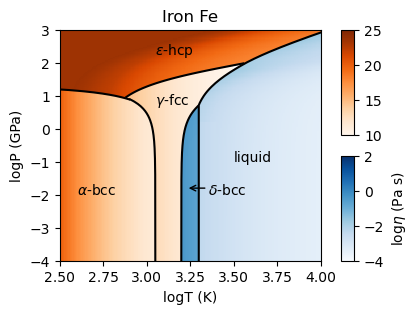

In [16]:
###Viscosity of Iron

fig = plt.figure(figsize=(3.8,3))

# Grid: main plot on left, two stacked colorbars on right
gs = fig.add_gridspec(2, 2, width_ratios=[20, 1], wspace=0.15)
ax = fig.add_subplot(gs[:, 0])        # main axes
cax_low  = fig.add_subplot(gs[1, 1])  # bottom colorbar
cax_high = fig.add_subplot(gs[0, 1])  # top colorbar

# Phase boundaries
T_melt = np.zeros_like(P_range)
for i in range(len(P_range)):
    T_melt[i] = iron_solidus(P_range[i])
T_gamma_epsilon = gamma_epsilon_phase(P_range)
T_alpha_gamma   = alpha_gamma_phase(P_range)
T_delta_gamma   = delta_gamma_phase(P_range)
T_alpha_epsilon = alpha_epsilon_phase(P_range)

#Plotting the boundaries
ax.plot(np.log10(T_delta_gamma[T_delta_gamma<T_melt]), np.log10(P_range[T_delta_gamma<T_melt]),color='k')
ax.plot(np.log10(T_alpha_gamma[T_alpha_gamma<T_alpha_epsilon+1e1]), np.log10(P_range[T_alpha_gamma<T_alpha_epsilon+1e1]),color='k')
ax.plot(np.log10(T_alpha_epsilon[T_alpha_gamma>T_alpha_epsilon]), np.log10(P_range[T_alpha_gamma>T_alpha_epsilon]),color='k')
ax.plot(np.log10(T_gamma_epsilon[(P_range<2e2)&(T_gamma_epsilon<T_melt)&(T_gamma_epsilon>T_alpha_epsilon)]), np.log10(P_range[(P_range<2e2)&(T_gamma_epsilon<T_melt)&(T_gamma_epsilon>T_alpha_epsilon)]),color='k')
ax.plot(np.log10(T_melt), np.log10(P_range),color='black')

# We use a broken colorbars due to the large OOM range covered by viscosity

# Masked ranges
#Liquid/near-liquid low values
logeta_low  = np.ma.masked_outside(logeta_iron.T, -4, 2)
#High creep solid values
logeta_high = np.ma.masked_outside(logeta_iron.T, 10, 30)

# Two different colormaps for each regions
cmap_low  = plt.cm.Blues
cmap_high = plt.cm.Oranges

# Plot masked layers in color meshes
pcm_low = ax.pcolormesh(logT_grid, logP_grid, logeta_low,
                        cmap=cmap_low, vmin=-4, vmax=2, rasterized=True)

pcm_high = ax.pcolormesh(logT_grid, logP_grid, logeta_high,
                         cmap=cmap_high, vmin=10, vmax=25, rasterized=True)

# Bottom colorbar: -4 to -1
cbar_low = fig.colorbar(pcm_low, cax=cax_low)
cbar_low.set_label('log$\\eta$ (Pa s)')
cbar_low.ax.set_ylim(-4, 2)
cbar_low.ax.spines['top'].set_visible(False)

# Top colorbar: 10 to 25
cbar_high = fig.colorbar(pcm_high, cax=cax_high)
cbar_high.ax.set_ylim(10, 25)
cbar_high.ax.spines['bottom'].set_visible(False)

#labels
ax.annotate('liquid',(3.5,-1),color='black')
ax.annotate('$\\varepsilon$-hcp',(3.05,2.25),color='black')
ax.annotate('$\\gamma$-fcc',(3.05,0.75),color='black')
ax.annotate('$\\alpha$-bcc',(2.6,-2),color='black')
ax.annotate('$\\delta$-bcc',(3.35,-2),color='black')
ax.annotate(
    "", xy=(3.225, -1.8), xytext=(3.35, -1.8),
    arrowprops=dict(arrowstyle="->", lw=1, color="black")
)


#Finalize and save the figure
ax.set_title('Iron Fe')
ax.set_xlim((2.5, 4))
ax.set_ylim((-4, 3))
ax.set_xlabel('logT (K)')
ax.set_ylabel('logP (GPa)')
plt.savefig("core_eta_eff_EOS.pdf", bbox_inches='tight')

C:\Users\vince\AppData\Local\Temp\ipykernel_24644\2284017572.py:13: RuntimeWarning: invalid value encountered in log10
  ax.plot(np.log10(T_alpha_epsilon[T_alpha_gamma>T_alpha_epsilon]), np.log10(P_range[T_alpha_gamma>T_alpha_epsilon]),color='k')


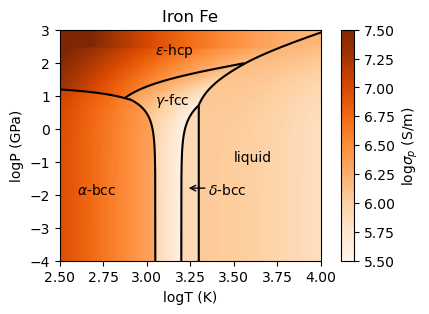

In [17]:
###Electrical conductivity of Iron

fig = plt.figure(figsize=(3.8,3))

# Grid: main plot on left, single colorbar on right
gs = fig.add_gridspec(1, 2, width_ratios=[20, 1], wspace=0.15)
ax = fig.add_subplot(gs[0, 0])        # main axes
cax = fig.add_subplot(gs[0, 1])       # single colorbar axis

#Plot the phase boundaries
ax.plot(np.log10(T_delta_gamma[T_delta_gamma<T_melt]), np.log10(P_range[T_delta_gamma<T_melt]),color='k')
ax.plot(np.log10(T_alpha_gamma[T_alpha_gamma<T_alpha_epsilon+1e1]), np.log10(P_range[T_alpha_gamma<T_alpha_epsilon+1e1]),color='k')
ax.plot(np.log10(T_alpha_epsilon[T_alpha_gamma>T_alpha_epsilon]), np.log10(P_range[T_alpha_gamma>T_alpha_epsilon]),color='k')
ax.plot(np.log10(T_gamma_epsilon[(P_range<2e2)&(T_gamma_epsilon<T_melt)&(T_gamma_epsilon>T_alpha_epsilon)]),
        np.log10(P_range[(P_range<2e2)&(T_gamma_epsilon<T_melt)&(T_gamma_epsilon>T_alpha_epsilon)]),color='k')
ax.plot(np.log10(T_melt), np.log10(P_range),color='black')


# Single colormap and normalization
cmap = plt.cm.Oranges
pcm = ax.pcolormesh(logT_grid, logP_grid, logsigma_iron.T,
                    cmap=cmap, vmin=5.5, vmax=7.5, rasterized=True)

# Correct colorbar placement
cbar = fig.colorbar(pcm, cax=cax)
cbar.set_label('log$\\sigma_p$ (S/m)')

#Phase labels
ax.annotate('liquid',(3.5,-1),color='black')
ax.annotate('$\\varepsilon$-hcp',(3.05,2.25),color='black')
ax.annotate('$\\gamma$-fcc',(3.05,0.75),color='black')
ax.annotate('$\\alpha$-bcc',(2.6,-2),color='black')
ax.annotate('$\\delta$-bcc',(3.35,-2),color='black')
ax.annotate(
    "", xy=(3.225, -1.8), xytext=(3.35, -1.8),
    arrowprops=dict(arrowstyle="->", lw=1, color="black")
)

#Finalize and save the figure
ax.set_title('Iron Fe')
ax.set_xlim((2.5, 4))
ax.set_ylim((-4, 3))
ax.set_xlabel('logT (K)')
ax.set_ylabel('logP (GPa)')
plt.savefig("core_sigma_p_EOS.pdf",  bbox_inches='tight')

C:\Users\vince\AppData\Local\Temp\ipykernel_24644\4206644020.py:12: RuntimeWarning: invalid value encountered in log10
  ax.plot(np.log10(T_alpha_epsilon[T_alpha_gamma>T_alpha_epsilon]), np.log10(P_range[T_alpha_gamma>T_alpha_epsilon]),color='k')


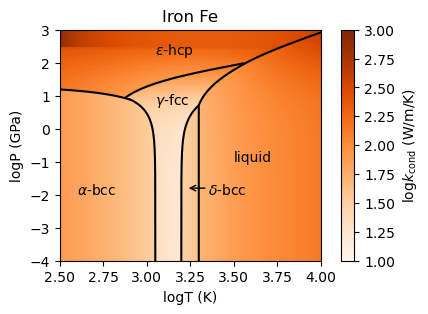

In [18]:
###Thermal conductivity of Iron
fig = plt.figure(figsize=(3.8,3))

# Grid: main plot on left, single colorbar on right
gs = fig.add_gridspec(1, 2, width_ratios=[20, 1], wspace=0.15)
ax = fig.add_subplot(gs[0, 0])        # main axes
cax = fig.add_subplot(gs[0, 1])       # single colorbar axis

#Plot the phase boundaries
ax.plot(np.log10(T_delta_gamma[T_delta_gamma<T_melt]), np.log10(P_range[T_delta_gamma<T_melt]),color='k')
ax.plot(np.log10(T_alpha_gamma[T_alpha_gamma<T_alpha_epsilon+1e1]), np.log10(P_range[T_alpha_gamma<T_alpha_epsilon+1e1]),color='k')
ax.plot(np.log10(T_alpha_epsilon[T_alpha_gamma>T_alpha_epsilon]), np.log10(P_range[T_alpha_gamma>T_alpha_epsilon]),color='k')
ax.plot(np.log10(T_gamma_epsilon[(P_range<2e2)&(T_gamma_epsilon<T_melt)&(T_gamma_epsilon>T_alpha_epsilon)]),
        np.log10(P_range[(P_range<2e2)&(T_gamma_epsilon<T_melt)&(T_gamma_epsilon>T_alpha_epsilon)]),color='k')
ax.plot(np.log10(T_melt), np.log10(P_range),color='black')

# Single colormap and normalization
cmap = plt.cm.Oranges
pcm = ax.pcolormesh(logT_grid, logP_grid,logk_cond_iron.T,
                    cmap=cmap, vmin=1, vmax=3, rasterized=True)

# Correct colorbar placement
cbar = fig.colorbar(pcm, cax=cax)
cbar.set_label('log$k_{\\rm cond}$ (W/m/K)')

#Phase labels
ax.annotate('liquid',(3.5,-1),color='black')
ax.annotate('$\\varepsilon$-hcp',(3.05,2.25),color='black')
ax.annotate('$\\gamma$-fcc',(3.05,0.75),color='black')
ax.annotate('$\\alpha$-bcc',(2.6,-2),color='black')
ax.annotate('$\\delta$-bcc',(3.35,-2),color='black')
ax.annotate(
    "", xy=(3.225, -1.8), xytext=(3.35, -1.8),
    arrowprops=dict(arrowstyle="->", lw=1, color="black")
)

#Finalize and save the Figure
ax.set_title('Iron Fe')
ax.set_xlim((2.5, 4))
ax.set_ylim((-4, 3))
ax.set_xlabel('logT (K)')
ax.set_ylabel('logP (GPa)')
plt.savefig("core_k_cond_EOS.pdf",  bbox_inches='tight')

### Save the grids

In [19]:
#Save the grids with the other PALEOS data
os.chdir(main_directory+'//EOS_Data')

### Viscosity
np.savetxt("logeta_enstatite.csv",logeta_enstatite, delimiter=',')
np.savetxt("logeta_iron.csv",logeta_iron, delimiter=',')

### Electrical conductivity
np.savetxt("logsigma_enstatite.csv",logsigma_enstatite, delimiter=',')
np.savetxt("logsigma_iron.csv",logsigma_iron, delimiter=',')

### Thermal conductivity
np.savetxt("logk_cond_enstatite.csv",logk_cond_enstatite, delimiter=',')
np.savetxt("logk_cond_iron.csv",logk_cond_iron, delimiter=',')